# EconoCausal — Promotion Analysis with DoWhy and EconML DML

This notebook uses the team's existing `transaction_weekly_final.csv` and `promotion_features.csv`; it does not redo the feature-engineering notebook or the earlier price-proxy analysis. It validates the key-level join, defines the only treatment contrast the engineered columns support, attempts DoWhy and EconML estimation only when there is adequate treatment variation, and exports CSV results.

**Measurement limitation:** the team's `display_code_count` and `mailer_code_count` were produced with `nunique()` on original categorical codes. Thus `count > 1` means multiple distinct codes were observed for a product–store–week, not necessarily that a promotion occurred. Results are labelled *multiple-code contrasts*, never automatically “promotion effects.” Missing promotion matches are not recoded as untreated. A causal claim still requires validated code semantics and defensible confounding assumptions.

In [2]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd

RANDOM_STATE = 42
MAX_MODEL_ROWS = 100_000
MIN_GROUP_SIZE = 200
MIN_PREVALENCE = 0.01
KEYS = ["PRODUCT_ID", "STORE_ID", "WEEK_NO"]

def find_root(start=None):
    p = Path.cwd() if start is None else Path(start)
    for q in [p, *p.parents]:
        if (q / "Output" / "causal output" / "Output" / "transaction_weekly_final.csv").exists():
            return q
        if (q / "transaction_weekly_final.csv").exists():
            return q
    return p.parent if p.name.lower() == "dowhy" else p

PROJECT_ROOT = find_root()
DATA_DIR = PROJECT_ROOT / "Output" / "causal output" / "Output"
WEEKLY_PATH = DATA_DIR / "transaction_weekly_final.csv"
PROMOTION_PATH = DATA_DIR / "promotion_features.csv"
RESULTS_DIR = PROJECT_ROOT / "outputs" / "causal_results"

# If the files are stored elsewhere, edit these two paths only.
print("Project root:", PROJECT_ROOT)
print("Weekly file exists:", WEEKLY_PATH.exists(), WEEKLY_PATH)
print("Promotion file exists:", PROMOTION_PATH.exists(), PROMOTION_PATH)

Project root: d:\Econocausal Double machine learning project\EconoCausal-Dynamic-Pricing-via-Double-Machine-Learning
Weekly file exists: True d:\Econocausal Double machine learning project\EconoCausal-Dynamic-Pricing-via-Double-Machine-Learning\Output\causal output\Output\transaction_weekly_final.csv
Promotion file exists: True d:\Econocausal Double machine learning project\EconoCausal-Dynamic-Pricing-via-Double-Machine-Learning\Output\causal output\Output\promotion_features.csv


## 1. Load existing engineered data

Only required columns are loaded. The feature engineering itself is not rerun.

In [3]:
if not WEEKLY_PATH.exists() or not PROMOTION_PATH.exists():
    raise FileNotFoundError("Set WEEKLY_PATH and PROMOTION_PATH in the configuration cell to the existing engineered CSV files.")

weekly_header = pd.read_csv(WEEKLY_PATH, nrows=0).columns.tolist()
promo_header = pd.read_csv(PROMOTION_PATH, nrows=0).columns.tolist()
weekly_cols = [c for c in [*KEYS, "TOTAL_QUANTITY", "TOTAL_SALES", "TOTAL_RETAIL_DISC", "TOTAL_COUPON_DISC", "TOTAL_COUPON_MATCH_DISC"] if c in weekly_header]
promo_cols = [c for c in [*KEYS, "display_code_count", "mailer_code_count"] if c in promo_header]
weekly_data = pd.read_csv(WEEKLY_PATH, usecols=weekly_cols)
promotion_features = pd.read_csv(PROMOTION_PATH, usecols=promo_cols)

required_w = set(KEYS + ["TOTAL_QUANTITY"])
required_p = set(KEYS + ["display_code_count", "mailer_code_count"])
if not required_w.issubset(weekly_data.columns):
    raise ValueError(f"Weekly file lacks columns: {sorted(required_w-set(weekly_data.columns))}")
if not required_p.issubset(promotion_features.columns):
    raise ValueError(f"Promotion file lacks columns: {sorted(required_p-set(promotion_features.columns))}")
print("Weekly shape:", weekly_data.shape, "| Promotion shape:", promotion_features.shape)

Weekly shape: (2370784, 8) | Promotion shape: (36771279, 5)


## 2. Validate and merge by product–store–week

The merge is many-to-one and must not multiply weekly rows. Unmatched keys remain missing rather than being treated as non-promoted.

In [4]:
for df in [weekly_data, promotion_features]:
    for k in KEYS:
        df[k] = pd.to_numeric(df[k], errors="coerce")

n_duplicate_promo_keys = int(promotion_features.duplicated(KEYS).sum())
if n_duplicate_promo_keys:
    raise ValueError(f"Promotion feature file contains {n_duplicate_promo_keys:,} duplicate product-store-week keys; stopping to avoid row multiplication.")

rows_before = len(weekly_data)
analysis = weekly_data.merge(promotion_features, on=KEYS, how="left", validate="many_to_one", indicator="_merge_status")
if len(analysis) != rows_before:
    raise AssertionError("Merge changed the weekly row count.")
analysis["PROMOTION_KEY_MATCHED"] = analysis["_merge_status"].eq("both").astype("int8")
join_summary = pd.DataFrame([{
    "weekly_rows_before": rows_before, "rows_after_merge": len(analysis),
    "matched_rows": int(analysis.PROMOTION_KEY_MATCHED.sum()),
    "unmatched_rows": int((analysis.PROMOTION_KEY_MATCHED == 0).sum()),
    "match_rate_pct": round(100*analysis.PROMOTION_KEY_MATCHED.mean(), 4),
    "duplicate_promotion_keys": n_duplicate_promo_keys
}])
display(join_summary)

,weekly_rows_before,rows_after_merge,matched_rows,unmatched_rows,match_rate_pct,duplicate_promotion_keys
0,2370784,2370784,483320,1887464,20.3865,0


## 3. Define treatment contrasts conservatively

`*_code_count > 1` means multiple distinct codes, not confirmed promotion exposure. The explicit names prevent the results from being misreported.

In [5]:
analysis["DISPLAY_MULTIPLE_CODES"] = np.where(analysis["display_code_count"].notna(), (analysis["display_code_count"] > 1).astype("int8"), np.nan)
analysis["MAILER_MULTIPLE_CODES"] = np.where(analysis["mailer_code_count"].notna(), (analysis["mailer_code_count"] > 1).astype("int8"), np.nan)

treatment_specs = [
    ("DISPLAY_MULTIPLE_CODES", "display_multiple_codes"),
    ("MAILER_MULTIPLE_CODES", "mailer_multiple_codes")
]
rows = []
for col, label in treatment_specs:
    s = analysis[col].dropna()
    n1, n0 = int((s == 1).sum()), int((s == 0).sum())
    rows.append({"treatment":label,"observed_rows":len(s),"treated_rows":n1,"control_rows":n0,"treated_prevalence_pct":round(100*n1/len(s),6) if len(s) else np.nan,"meaning":"multiple distinct codes vs one code; not confirmed promotion exposure"})
treatment_balance = pd.DataFrame(rows)
display(treatment_balance)

,treatment,observed_rows,treated_rows,control_rows,treated_prevalence_pct,meaning
0,display_multiple_codes,483320,615,482705,0.127245,multiple distinct codes vs one code; not confi...
1,mailer_multiple_codes,483320,1,483319,0.000207,multiple distinct codes vs one code; not confi...


## 4. DoWhy identification and exploratory estimate

Product, store, and week are adjusted for as observed covariates. This does not guarantee that unmeasured confounding is absent. Treatments with rare exposure or too few observations in either group are not estimated.

In [6]:
from dowhy import CausalModel

GRAPH = """
digraph {
    PRODUCT_ID -> TREATMENT;
    STORE_ID -> TREATMENT;
    WEEK_NO -> TREATMENT;
    PRODUCT_ID -> TOTAL_QUANTITY;
    STORE_ID -> TOTAL_QUANTITY;
    WEEK_NO -> TOTAL_QUANTITY;
    TREATMENT -> TOTAL_QUANTITY;
}
"""

def eligible_frame(treatment_col):
    d = analysis[KEYS + [treatment_col, "TOTAL_QUANTITY"]].replace([np.inf, -np.inf], np.nan).dropna().copy()
    d = d[d[treatment_col].isin([0,1]) & (d["TOTAL_QUANTITY"] >= 0)]
    return d

def enough_variation(d, col):
    n1 = int((d[col] == 1).sum()); n0 = int((d[col] == 0).sum())
    prevalence = n1/len(d) if len(d) else 0
    return n1 >= MIN_GROUP_SIZE and n0 >= MIN_GROUP_SIZE and prevalence >= MIN_PREVALENCE, n1, n0, prevalence

dowhy_rows, fitted_dowhy = [], {}
for tcol, label in treatment_specs:
    d = eligible_frame(tcol)
    ok, n1, n0, prevalence = enough_variation(d, tcol)
    if not ok:
        dowhy_rows.append({"treatment":label,"status":"NOT_ESTIMATED","n":len(d),"treated_n":n1,"control_n":n0,"prevalence_pct":round(100*prevalence,6),"ate":np.nan,"details":"Insufficient treatment variation/overlap under preset safeguards."})
        continue
    if len(d) > MAX_MODEL_ROWS:
        d = d.sample(MAX_MODEL_ROWS, random_state=RANDOM_STATE)
    n1, n0 = int((d[tcol] == 1).sum()), int((d[tcol] == 0).sum())
    if min(n1,n0) < MIN_GROUP_SIZE:
        dowhy_rows.append({"treatment":label,"status":"NOT_ESTIMATED_AFTER_SAMPLE","n":len(d),"treated_n":n1,"control_n":n0,"prevalence_pct":round(100*n1/len(d),6),"ate":np.nan,"details":"A treatment group became too small after reproducible sampling."})
        continue
    d = d.rename(columns={tcol:"TREATMENT"})
    model = CausalModel(data=d, treatment="TREATMENT", outcome="TOTAL_QUANTITY", graph=GRAPH)
    estimand = model.identify_effect(proceed_when_unidentifiable=False)
    estimate = model.estimate_effect(estimand, method_name="backdoor.linear_regression", target_units="ate")
    dowhy_rows.append({"treatment":label,"status":"ESTIMATED_EXPLORATORY","n":len(d),"treated_n":int((d.TREATMENT==1).sum()),"control_n":int((d.TREATMENT==0).sum()),"prevalence_pct":round(100*(d.TREATMENT==1).mean(),6),"ate":float(estimate.value),"details":"Exploratory estimate for multiple-code contrast; causal assumptions remain unverified."})
    fitted_dowhy[label] = (model, estimand, estimate)

dowhy_results = pd.DataFrame(dowhy_rows)
display(dowhy_results)

d:\EconoCausal_Env\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,treatment,status,n,treated_n,control_n,prevalence_pct,ate,details
0,display_multiple_codes,NOT_ESTIMATED,483320,615,482705,0.127245,NaN,Insufficient treatment variation/overlap under...
1,mailer_multiple_codes,NOT_ESTIMATED,483320,1,483319,0.000207,NaN,Insufficient treatment variation/overlap under...


## 5. DoWhy refutation

A random-common-cause refutation is attempted only for treatments that passed the safeguards. A refutation test is a sensitivity check, not proof of causality.

In [7]:
refutation_rows = []
for label, (model, estimand, estimate) in fitted_dowhy.items():
    try:
        ref = model.refute_estimate(estimand, estimate, method_name="random_common_cause", random_state=RANDOM_STATE)
        refutation_rows.append({"treatment":label,"method":"random_common_cause","status":"COMPLETED","original_estimate":float(estimate.value),"new_effect":float(getattr(ref,"new_effect",np.nan)),"details":str(ref)})
    except Exception as e:
        refutation_rows.append({"treatment":label,"method":"random_common_cause","status":"ERROR","original_estimate":float(estimate.value),"new_effect":np.nan,"details":repr(e)})
refutation_results = pd.DataFrame(refutation_rows, columns=["treatment","method","status","original_estimate","new_effect","details"])
if refutation_results.empty:
    refutation_results = pd.DataFrame([{"treatment":"ALL","method":"random_common_cause","status":"NOT_RUN","original_estimate":np.nan,"new_effect":np.nan,"details":"No treatment passed the variation safeguards."}])
display(refutation_results)

,treatment,method,status,original_estimate,new_effect,details
0,ALL,random_common_cause,NOT_RUN,NaN,NaN,No treatment passed the variation safeguards.


## 6. EconML Double Machine Learning

`LinearDML` uses a binary-treatment propensity model and a regularized outcome model, with product/store/week represented as categorical controls. A reproducible maximum sample size avoids an unexpectedly expensive full-data fit. DML is skipped if the treatment lacks overlap. This remains an exploratory multiple-code contrast, not confirmed promotion exposure.

In [8]:
from econml.dml import LinearDML
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression, Ridge


def fit_dml(tcol, label):
    d = eligible_frame(tcol)
    ok, n1, n0, prev = enough_variation(d, tcol)
    if not ok:
        return {"treatment":label,"status":"NOT_ESTIMATED","n":len(d),"treated_n":n1,"control_n":n0,"prevalence_pct":round(100*prev,6),"ate":np.nan,"ci_lower":np.nan,"ci_upper":np.nan,"details":"Insufficient treatment variation/overlap under preset safeguards."}
    if len(d) > MAX_MODEL_ROWS:
        d = d.sample(MAX_MODEL_ROWS, random_state=RANDOM_STATE).copy()
    n1, n0 = int((d[tcol]==1).sum()), int((d[tcol]==0).sum())
    if min(n1,n0) < MIN_GROUP_SIZE:
        return {"treatment":label,"status":"NOT_ESTIMATED_AFTER_SAMPLE","n":len(d),"treated_n":n1,"control_n":n0,"prevalence_pct":round(100*n1/len(d),6),"ate":np.nan,"ci_lower":np.nan,"ci_upper":np.nan,"details":"A treatment group became too small after sampling."}
    enc = OneHotEncoder(handle_unknown="ignore", min_frequency=20)
    W = enc.fit_transform(d[KEYS])
    T = d[tcol].to_numpy(dtype=int)
    Y = d["TOTAL_QUANTITY"].to_numpy(dtype=float)
    X = np.ones((len(d),1))  # constant effect: average treatment effect
    model = LinearDML(model_y=Ridge(alpha=10.0), model_t=LogisticRegression(max_iter=1000), discrete_treatment=True, cv=3, random_state=RANDOM_STATE)
    model.fit(Y, T, X=X, W=W)
    ate = float(np.asarray(model.ate(X=X)).reshape(-1)[0])
    ci = model.ate_interval(X=X, alpha=0.05)
    lo, hi = float(np.asarray(ci[0]).reshape(-1)[0]), float(np.asarray(ci[1]).reshape(-1)[0])
    return {"treatment":label,"status":"ESTIMATED_EXPLORATORY","n":len(d),"treated_n":n1,"control_n":n0,"prevalence_pct":round(100*n1/len(d),6),"ate":ate,"ci_lower":lo,"ci_upper":hi,"details":"ATE for multiple-code contrast; not confirmed promotion exposure. Causal assumptions remain unverified."}

dml_rows = []
for tcol, label in treatment_specs:
    try:
        dml_rows.append(fit_dml(tcol,label))
    except Exception as e:
        dml_rows.append({"treatment":label,"status":"ERROR","n":np.nan,"treated_n":np.nan,"control_n":np.nan,"prevalence_pct":np.nan,"ate":np.nan,"ci_lower":np.nan,"ci_upper":np.nan,"details":repr(e)})
dml_results = pd.DataFrame(dml_rows)
display(dml_results)

,treatment,status,n,treated_n,control_n,prevalence_pct,ate,ci_lower,ci_upper,details
0,display_multiple_codes,NOT_ESTIMATED,483320,615,482705,0.127245,NaN,NaN,NaN,Insufficient treatment variation/overlap under...
1,mailer_multiple_codes,NOT_ESTIMATED,483320,1,483319,0.000207,NaN,NaN,NaN,Insufficient treatment variation/overlap under...


## 7. Export downloadable CSV results

Run this final cell after the model cells. It saves the result CSVs in the local project at `outputs/causal_results/`. The status fields distinguish an actual estimate from a skipped or failed fit; do not report skipped estimates as zero.

In [9]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
join_summary.to_csv(RESULTS_DIR / "01_join_validation.csv", index=False)
treatment_balance.to_csv(RESULTS_DIR / "02_treatment_balance.csv", index=False)
dowhy_results.to_csv(RESULTS_DIR / "03_dowhy_results.csv", index=False)
refutation_results.to_csv(RESULTS_DIR / "04_dowhy_refutation.csv", index=False)
dml_results.to_csv(RESULTS_DIR / "05_econml_dml_results.csv", index=False)
combined = pd.concat([
    dowhy_results.assign(model="DoWhy"),
    dml_results.assign(model="EconML_LinearDML")
], ignore_index=True, sort=False)
combined.to_csv(RESULTS_DIR / "06_combined_model_summary.csv", index=False)
metadata = {
    "project_root": str(PROJECT_ROOT), "weekly_path": str(WEEKLY_PATH), "promotion_path": str(PROMOTION_PATH),
    "weekly_rows": int(len(weekly_data)), "merged_rows": int(len(analysis)),
    "matched_rows": int(analysis.PROMOTION_KEY_MATCHED.sum()),
    "unmatched_rows": int((analysis.PROMOTION_KEY_MATCHED==0).sum()),
    "treatments": {"DISPLAY_MULTIPLE_CODES":"display_code_count > 1", "MAILER_MULTIPLE_CODES":"mailer_code_count > 1"},
    "warning":"Multiple distinct codes are not confirmed promotion exposure. Validate source-code semantics before making causal claims."
}
with open(RESULTS_DIR / "run_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)
print("Saved results to:", RESULTS_DIR)
for path in sorted(RESULTS_DIR.iterdir()):
    print(path.name, f"({path.stat().st_size:,} bytes)")

Saved results to: d:\Econocausal Double machine learning project\EconoCausal-Dynamic-Pricing-via-Double-Machine-Learning\outputs\causal_results
01_join_validation.csv (147 bytes)
02_treatment_balance.csv (321 bytes)
03_dowhy_results.csv (328 bytes)
04_dowhy_refutation.csv (143 bytes)
05_econml_dml_results.csv (350 bytes)
06_combined_model_summary.csv (667 bytes)
run_metadata.json (887 bytes)


## Final interpretation checklist

- Report only rows whose `status` starts with `ESTIMATED`; do not interpret `NOT_ESTIMATED` as an effect of zero.
- Use the exact treatment description **multiple distinct codes vs one code** unless the original codes' semantics are validated.
- A successful DoWhy/EconML fit does not prove causality; consider unmeasured confounding, treatment assignment, temporal ordering, and the promotion matching process.
- The exported CSVs are the auditable final outputs of this notebook run.

In [10]:
from pathlib import Path
import pandas as pd

print("Weekly file:", WEEKLY_PATH)
print("Exists:", WEEKLY_PATH.exists())

# Read only the header and a small sample.
print("\nColumns:")
print(pd.read_csv(WEEKLY_PATH, nrows=0).columns.tolist())

sample = pd.read_csv(WEEKLY_PATH, nrows=5)
print("\nSample:")
display(sample)



Weekly file: d:\Econocausal Double machine learning project\EconoCausal-Dynamic-Pricing-via-Double-Machine-Learning\Output\causal output\Output\transaction_weekly_final.csv
Exists: True

Columns:


['PRODUCT_ID', 'STORE_ID', 'WEEK_NO', 'TOTAL_QUANTITY', 'TOTAL_SALES', 'TOTAL_RETAIL_DISC', 'TOTAL_COUPON_DISC', 'TOTAL_COUPON_MATCH_DISC', 'TRANSACTION_ROWS', 'UNIQUE_BASKETS', 'ZERO_QUANTITY_ROWS', 'ZERO_SALES_ROWS', 'EXTREME_QUANTITY_ROWS', 'PRICE_PROXY', 'ZERO_OR_NEGATIVE_QUANTITY_FLAG', 'ZERO_SALES_FLAG', 'MISSING_PRICE_PROXY_FLAG', 'EXTREME_QUANTITY_FLAG', 'NONPOSITIVE_PRICE_PROXY_FLAG']

Sample:


,PRODUCT_ID,STORE_ID,WEEK_NO,TOTAL_QUANTITY,TOTAL_SALES,TOTAL_RETAIL_DISC,TOTAL_COUPON_DISC,TOTAL_COUPON_MATCH_DISC,TRANSACTION_ROWS,UNIQUE_BASKETS,ZERO_QUANTITY_ROWS,ZERO_SALES_ROWS,EXTREME_QUANTITY_ROWS,PRICE_PROXY,ZERO_OR_NEGATIVE_QUANTITY_FLAG,ZERO_SALES_FLAG,MISSING_PRICE_PROXY_FLAG,EXTREME_QUANTITY_FLAG,NONPOSITIVE_PRICE_PROXY_FLAG
0,25671,3191,59,4,13.96,0.0,0.0,0.0,1,1,0,0,0,3.49,0,0,0,0,0
1,25671,3266,36,1,3.49,0.0,0.0,0.0,1,1,0,0,0,3.49,0,0,0,0,0
2,25671,3313,23,1,3.49,0.0,0.0,0.0,1,1,0,0,0,3.49,0,0,0,0,0
3,26081,3235,36,1,0.99,0.0,0.0,0.0,1,1,0,0,0,0.99,0,0,0,0,0
4,26093,33904,66,1,1.59,0.0,0.0,0.0,1,1,0,0,0,1.59,0,0,0,0,0


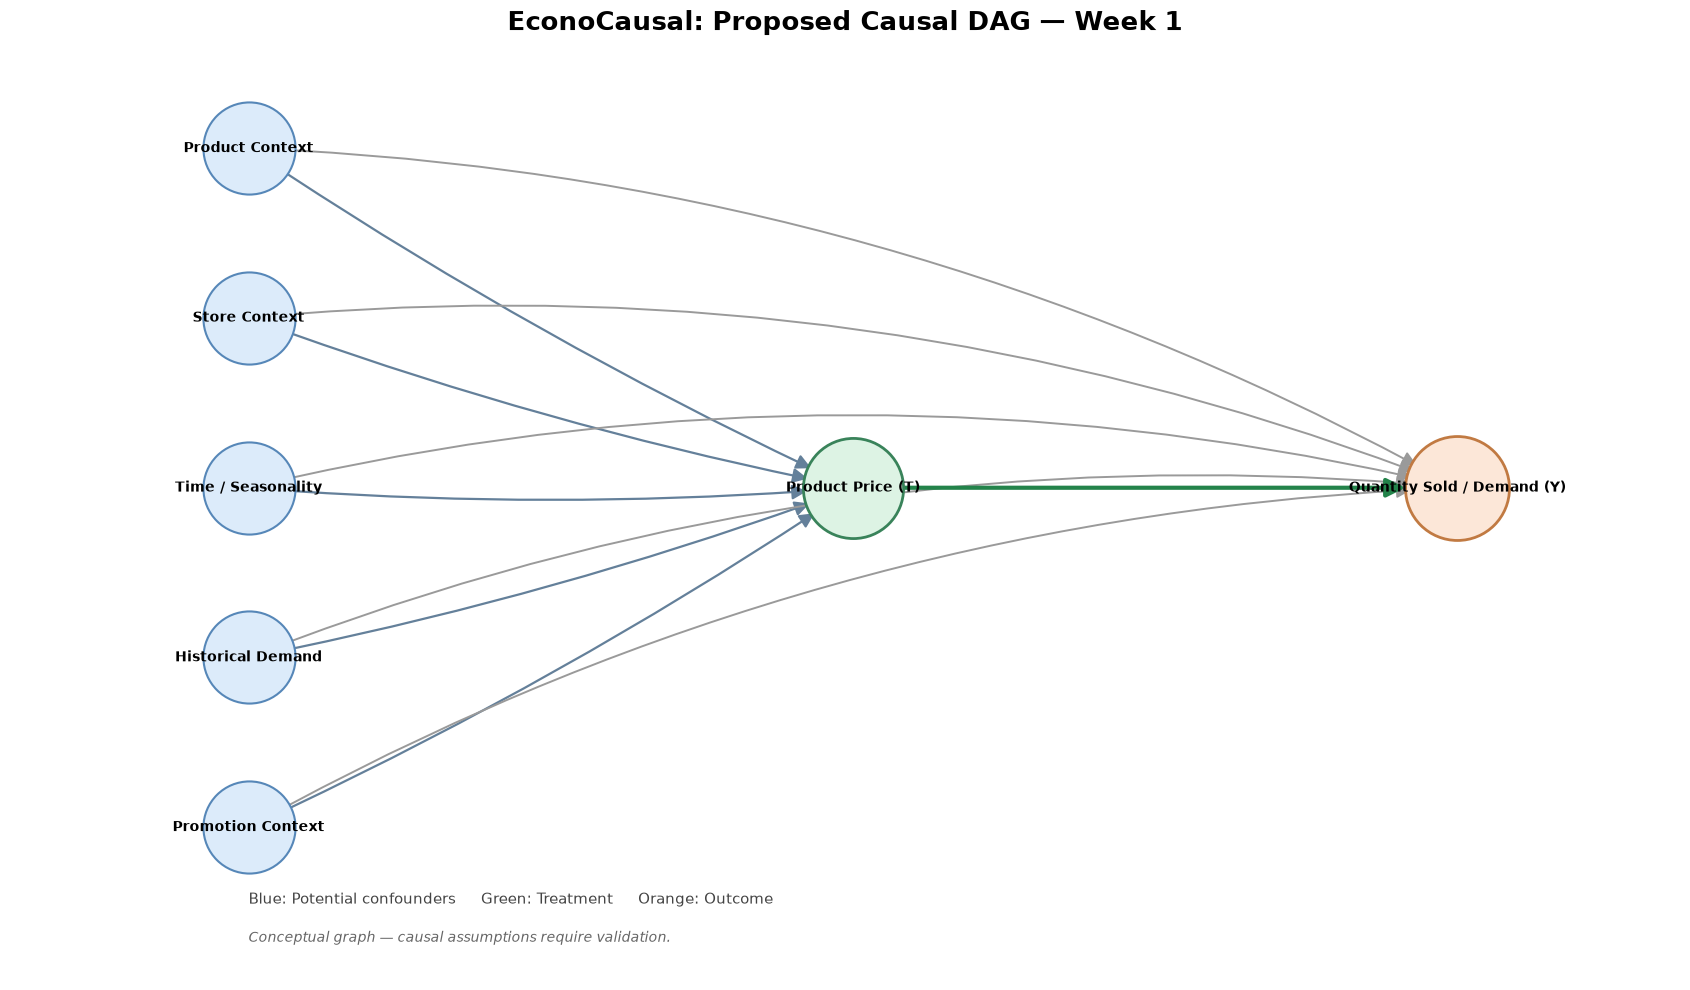

Readable DAG saved to: d:\Econocausal Double machine learning project\EconoCausal-Dynamic-Pricing-via-Double-Machine-Learning\Dowhy\EconoCausal_Week1_DAG.png


In [14]:
import matplotlib.pyplot as plt
import networkx as nx
from pathlib import Path

# EconoCausal — Week 1 Proposed Causal DAG
G = nx.DiGraph()

# Define nodes
confounders = [
    "Product Context",
    "Store Context",
    "Time / Seasonality",
    "Historical Demand",
    "Promotion Context",
]

treatment = "Product Price (T)"
outcome = "Quantity Sold / Demand (Y)"

G.add_nodes_from(confounders + [treatment, outcome])

# Proposed causal relationships
edges = [
    ("Product Context", treatment),
    ("Product Context", outcome),
    ("Store Context", treatment),
    ("Store Context", outcome),
    ("Time / Seasonality", treatment),
    ("Time / Seasonality", outcome),
    ("Historical Demand", treatment),
    ("Historical Demand", outcome),
    ("Promotion Context", treatment),
    ("Promotion Context", outcome),
    (treatment, outcome),
]
G.add_edges_from(edges)

# Manually arranged positions for readability
pos = {
    "Product Context": (0, 4),
    "Store Context": (0, 2),
    "Time / Seasonality": (0, 0),
    "Historical Demand": (0, -2),
    "Promotion Context": (0, -4),
    treatment: (3.8, 0),
    outcome: (7.6, 0),
}

fig, ax = plt.subplots(figsize=(17, 10))

# Draw potential confounders
nx.draw_networkx_nodes(
    G, pos,
    nodelist=confounders,
    node_color="#DCEBFA",
    node_size=4400,
    edgecolors="#5687B8",
    linewidths=1.5,
    ax=ax,
)

# Draw treatment
nx.draw_networkx_nodes(
    G, pos,
    nodelist=[treatment],
    node_color="#DDF3E4",
    node_size=5200,
    edgecolors="#39835A",
    linewidths=2,
    ax=ax,
)

# Draw outcome
nx.draw_networkx_nodes(
    G, pos,
    nodelist=[outcome],
    node_color="#FCE7D8",
    node_size=5600,
    edgecolors="#C17A42",
    linewidths=2,
    ax=ax,
)

# Draw readable labels
nx.draw_networkx_labels(
    G, pos,
    font_size=10,
    font_weight="bold",
    font_family="sans-serif",
    ax=ax,
)

# Draw arrows with gentle curvature to reduce overlap
for source in confounders:
    # Confounder -> treatment
    nx.draw_networkx_edges(
        G, pos,
        edgelist=[(source, treatment)],
        edge_color="#64809A",
        width=1.6,
        arrows=True,
        arrowsize=22,
        node_size=4400,
        connectionstyle="arc3,rad=0.04",
        min_source_margin=8,
        min_target_margin=12,
        ax=ax,
    )

    # Confounder -> outcome, curved in the opposite direction
    nx.draw_networkx_edges(
        G, pos,
        edgelist=[(source, outcome)],
        edge_color="#9A9A9A",
        width=1.4,
        arrows=True,
        arrowsize=22,
        node_size=4400,
        connectionstyle="arc3,rad=-0.12",
        min_source_margin=8,
        min_target_margin=12,
        ax=ax,
    )

# Main causal effect: price -> demand
nx.draw_networkx_edges(
    G, pos,
    edgelist=[(treatment, outcome)],
    edge_color="#23834A",
    width=3,
    arrows=True,
    arrowsize=28,
    node_size=5600,
    connectionstyle="arc3,rad=0",
    min_source_margin=12,
    min_target_margin=12,
    ax=ax,
)

ax.set_title(
    "EconoCausal: Proposed Causal DAG — Week 1",
    fontsize=19,
    fontweight="bold",
    pad=24,
)

ax.text(
    0, -4.9,
    "Blue: Potential confounders     Green: Treatment     Orange: Outcome",
    fontsize=11,
    color="#444444",
)

ax.text(
    0, -5.35,
    "Conceptual graph — causal assumptions require validation.",
    fontsize=10,
    style="italic",
    color="#666666",
)

ax.set_xlim(-1.5, 9)
ax.set_ylim(-5.8, 5)
ax.axis("off")
plt.tight_layout()

# Save a high-resolution image in the current Dowhy folder
output_path = Path.cwd() / "EconoCausal_Week1_DAG.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print(f"Readable DAG saved to: {output_path}")

In [16]:
import pandas as pd
from pathlib import Path

# EconoCausal — Week 1 Causal Variable Table

variables = [
    {
        "variable": "Product Price",
        "causal_role": "Treatment (T)",
        "proposed_measurement": "Verified product price at product-store-week level",
        "source_columns": "SALES_VALUE, QUANTITY, PRICE_PROXY",
        "causal_justification": "Primary treatment; investigate how price changes affect demand.",
        "timing_requirement": "Price must correspond to the defined treatment period.",
        "assumptions_to_validate": "Verify whether PRICE_PROXY represents actual unit price; investigate discounts, returns, and zero quantities.",
        "status": "Proposed - validation required"
    },
    {
        "variable": "Quantity Sold / Demand",
        "causal_role": "Outcome (Y)",
        "proposed_measurement": "TOTAL_QUANTITY at product-store-week level",
        "source_columns": "QUANTITY, TOTAL_QUANTITY",
        "causal_justification": "Measures the demand response to product price.",
        "timing_requirement": "Define the outcome period relative to price exposure.",
        "assumptions_to_validate": "Investigate zero, negative, and unusually large quantities.",
        "status": "Proposed - validation required"
    },
    {
        "variable": "Product Context",
        "causal_role": "Potential confounder",
        "proposed_measurement": "Product identity or verified product category",
        "source_columns": "PRODUCT_ID",
        "causal_justification": "Products may differ in pricing and baseline demand.",
        "timing_requirement": "Known before treatment assignment.",
        "assumptions_to_validate": "Review product coverage and encoding strategy.",
        "status": "Candidate - review causal role"
    },
    {
        "variable": "Store Context",
        "causal_role": "Potential confounder",
        "proposed_measurement": "Store identity",
        "source_columns": "STORE_ID",
        "causal_justification": "Stores may differ in pricing policies and demand.",
        "timing_requirement": "Known before treatment assignment.",
        "assumptions_to_validate": "Verify whether store context influences both price and demand.",
        "status": "Candidate - review causal role"
    },
    {
        "variable": "Time / Seasonality",
        "causal_role": "Potential confounder",
        "proposed_measurement": "Week or verified calendar features",
        "source_columns": "WEEK_NO, DAY",
        "causal_justification": "Pricing and demand may vary over time.",
        "timing_requirement": "Respect the timing of the price decision.",
        "assumptions_to_validate": "Verify the definitions of WEEK_NO and DAY.",
        "status": "Candidate - review causal role"
    },
    {
        "variable": "Historical Demand",
        "causal_role": "Potential confounder",
        "proposed_measurement": "Quantity sold in earlier periods",
        "source_columns": "QUANTITY, TOTAL_QUANTITY",
        "causal_justification": "Past demand may influence pricing decisions and future demand.",
        "timing_requirement": "Calculate using only periods before the treatment period.",
        "assumptions_to_validate": "Prevent future-information leakage when creating lag features.",
        "status": "Candidate - lag feature required"
    },
    {
        "variable": "Promotion Context",
        "causal_role": "Potential confounder",
        "proposed_measurement": "Verified display and mailer indicators",
        "source_columns": "display, mailer, display_code_count, mailer_code_count",
        "causal_justification": "Promotion assignment may relate to both price and demand.",
        "timing_requirement": "Verify promotion timing relative to price assignment.",
        "assumptions_to_validate": "Confirm original coding; code counts greater than one do not automatically establish promotion presence.",
        "status": "Candidate - coding validation required"
    }
]

# Create the table
causal_variable_table = pd.DataFrame(variables)

# Save beside the current notebook
output_path = Path.cwd() / "causal_variable_table.csv"
causal_variable_table.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

# Display and confirm
display(causal_variable_table)

print("\nCSV saved successfully!")
print(f"Location: {output_path.resolve()}")
print(f"Rows: {len(causal_variable_table)}")
print(f"Columns: {len(causal_variable_table.columns)}")

,variable,causal_role,proposed_measurement,source_columns,causal_justification,timing_requirement,assumptions_to_validate,status
0,Product Price,Treatment (T),Verified product price at product-store-week l...,"SALES_VALUE, QUANTITY, PRICE_PROXY",Primary treatment; investigate how price chang...,Price must correspond to the defined treatment...,Verify whether PRICE_PROXY represents actual u...,Proposed - validation required
1,Quantity Sold / Demand,Outcome (Y),TOTAL_QUANTITY at product-store-week level,"QUANTITY, TOTAL_QUANTITY",Measures the demand response to product price.,Define the outcome period relative to price ex...,"Investigate zero, negative, and unusually larg...",Proposed - validation required
2,Product Context,Potential confounder,Product identity or verified product category,PRODUCT_ID,Products may differ in pricing and baseline de...,Known before treatment assignment.,Review product coverage and encoding strategy.,Candidate - review causal role
3,Store Context,Potential confounder,Store identity,STORE_ID,Stores may differ in pricing policies and demand.,Known before treatment assignment.,Verify whether store context influences both p...,Candidate - review causal role
4,Time / Seasonality,Potential confounder,Week or verified calendar features,"WEEK_NO, DAY",Pricing and demand may vary over time.,Respect the timing of the price decision.,Verify the definitions of WEEK_NO and DAY.,Candidate - review causal role
5,Historical Demand,Potential confounder,Quantity sold in earlier periods,"QUANTITY, TOTAL_QUANTITY",Past demand may influence pricing decisions an...,Calculate using only periods before the treatm...,Prevent future-information leakage when creati...,Candidate - lag feature required
6,Promotion Context,Potential confounder,Verified display and mailer indicators,"display, mailer, display_code_count, mailer_co...",Promotion assignment may relate to both price ...,Verify promotion timing relative to price assi...,Confirm original coding; code counts greater t...,Candidate - coding validation required



CSV saved successfully!
Location: D:\Econocausal Double machine learning project\EconoCausal-Dynamic-Pricing-via-Double-Machine-Learning\Dowhy\causal_variable_table.csv
Rows: 7
Columns: 8
